# Helen Mezgebe 
**I want to learn machine learning to understand data, build smart software, and fix real problems. I love learning new things about technology. My goal is to practice with data and code every day so I can make helpful tools for the future.**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df_titanic = pd.read_csv("train.csv")

In [ ]:
print(f"Dataset loaded: {df_titanic.shape[0]} rows, {df_titanic.shape[1]} columns")

Dataset loaded: 891 rows, 12 columns


In [ ]:
df_titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Preview Data

**df_titanic.head():** Displays the first 5 rows of your dataset.

In [ ]:
df_titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


# Check Data Info
**df_titanic.info()**: Shows data types, column names, and missing values.

In [ ]:
# Fill missing Embarked with the most common port
df_titanic['Embarked'] = df_titanic['Embarked'].fillna(df_titanic['Embarked'].mode()[0])

In [ ]:
# Fill missing Fare with median
df_titanic['Fare'] = df_titanic['Fare'].fillna(df_titanic['Fare'].median())

In [ ]:
# 1. Create the boolean mask for rows containing Master in the Name column
mask = df_titanic["Name"].str.contains("Master", na=False)

# 2. Calculate the mean age specifically for those rows
master_age_mean = df_titanic.loc[mask, "Age"].mean()

# 3. Fill missing Age values only for rows matching the mask
df_titanic.loc[mask, "Age"] = df_titanic.loc[mask, "Age"].fillna(master_age_mean)

In [ ]:
# 1. Create the boolean mask for Miss
mask_miss = df_titanic["Name"].str.contains("Miss", na=False)

# 2. Calculate the mean age specifically for those rows
miss_age_mean = df_titanic.loc[mask_miss, "Age"].mean()

# 3. Fill missing Age values only for rows matching the mask
df_titanic.loc[mask_miss, "Age"] = df_titanic.loc[mask_miss, "Age"].fillna(miss_age_mean)

In [ ]:
# 1. Create the boolean mask for Mrs
mask_mrs = df_titanic["Name"].str.contains("Mrs", na=False)

# 2. Calculate the mean age specifically for those rows
mrs_age_mean = df_titanic.loc[mask_mrs, "Age"].mean()

# 3. Fill missing Age values only for rows matching the mask
df_titanic.loc[mask_mrs, "Age"] = df_titanic.loc[mask_mrs, "Age"].fillna(mrs_age_mean)

In [ ]:
# 1. Create the boolean mask for Mr
mask_mr = df_titanic["Name"].str.contains("Mr", na=False)

# 2. Calculate the mean age specifically for those rows
mr_age_mean = df_titanic.loc[mask_mr, "Age"].mean()

# 3. Fill missing Age values only for rows matching the mask
df_titanic.loc[mask_mr, "Age"] = df_titanic.loc[mask_mr, "Age"].fillna(mr_age_mean)


In [ ]:
df_titanic['Age'] = df_titanic['Age'].fillna(df_titanic['Age'].median())


In [ ]:
# Extract title from Name using regex
df_titanic['Title'] = df_titanic['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

# Map rare titles to common groups
title_mapping = {
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Mrs", "Countess": "Mrs", "Dona": "Mrs",
    "Capt": "Mr", "Col": "Mr", "Don": "Mr", "Jonkheer": "Mr",
    "Major": "Mr", "Rev": "Mr", "Sir": "Mr", "Dr": "Mr"
}
df_titanic['Title'] = df_titanic['Title'].replace(title_mapping)

# Calculate subpopulation medians
title_medians = df_titanic.groupby('Title')['Age'].median()
print("Calculated Subpopulation Age Medians:\n", title_medians)

# Apply title-specific medians to missing ages
for title in title_medians.index:
    mask_title_null = (df_titanic['Title'] == title) & (df_titanic['Age'].isnull())
    df_titanic.loc[mask_title_null, 'Age'] = title_medians[title]

# Final backfill for any remaining nulls
df_titanic['Age'] = df_titanic['Age'].fillna(df_titanic['Age'].median())

Calculated Subpopulation Age Medians:
 Title
Master     4.000000
Miss      21.773973
Mr        33.199675
Mrs       35.642857
Name: Age, dtype: float64


In [ ]:
# Drop columns that are not useful for modeling
X = df_titanic.drop(["Survived", "PassengerId", "Name", "Ticket", "Cabin"], axis=1)

In [ ]:
y = df_titanic["Survived"]

In [ ]:
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,3,male,22.0,1,0,7.2500,S,Mr
1,1,female,38.0,1,0,71.2833,C,Mrs
2,3,female,26.0,0,0,7.9250,S,Miss
3,1,female,35.0,1,0,53.1000,S,Mrs
4,3,male,35.0,0,0,8.0500,S,Mr


In [ ]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

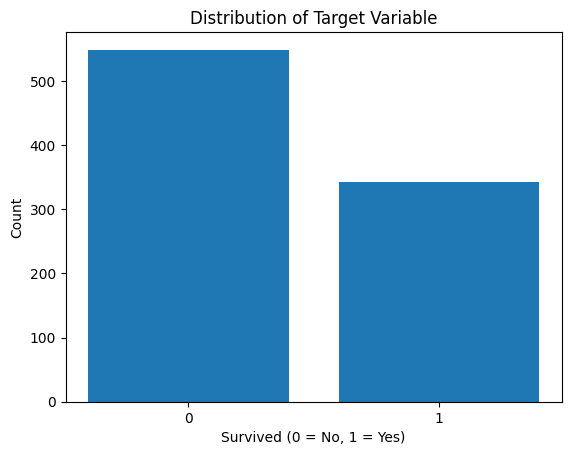

In [ ]:

counts = y.value_counts()
plt.bar(counts.index, counts)
plt.gca().set_xticks([0, 1])
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.title("Distribution of Target Variable")
plt.show()

# Plot Target Distribution

- **value_counts():** Counts how many passengers survived (1) and died (0).
- **plt.bar():** Creates a bar chart using those counts.
- **set_xticks([0, 1]):** Sets the chart labels exactly at 0 and 1.
- **plt.xlabel/ylabel/title:** Adds descriptive labels and a title to the graph.
- **plt.show():** Displays the completed bar chart on your screen.

In [ ]:
# %pip install scikit-learn

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
train = pd.DataFrame()
label = LabelEncoder()

for c in X.columns:
    if X[c].dtype == "object":
        train[c] = label.fit_transform(X[c].astype(str))
    else:
        train[c] = X[c]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
from sklearn import base

# Import Machine Learning Tools
- **train_test_split:** Splits data into training and testing sets.
- **LogisticRegression:** The model used to predict categories.
- **accuracy_score:** Measures the percentage of correct predictions.
- **KFold:** Splits data multiple times for cross-validation.
- **base:** Provides core scikit-learn building blocks.

In [ ]:
def logistic(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)
    
    lr = LogisticRegression(max_iter=5000)
    
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    print("Accuracy: ", accuracy_score(y_test, y_pred))

# Logistic Regression Function

- **train_test_split():** Splits data into 80% training and 20% testing.
- **LogisticRegression():** Creates the machine learning model.
- **lr.fit():** Trains the model on the training data.
- **lr.predict():** Makes predictions on the test data.
- **accuracy_score():** Prints the percentage of correct answers.


In [ ]:
X_baseline = train.copy()
X_baseline_clean = X_baseline.select_dtypes(include=['int64', 'float64'])

logistic(X_baseline_clean, y)

Accuracy:  0.8100558659217877


# Train Baseline Model

- **train.copy():** Creates a backup copy of the training data.
- **select_dtypes():**  Extracts only the number columns, removing all text.
- **logistic():**  Trains a baseline Logistic Regression model using only numbers.


In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
encoder_sex = OneHotEncoder(sparse_output=False)
one_hot_sex_df = pd.DataFrame(encoder_sex.fit_transform(X[['Sex']]), columns=encoder_sex.get_feature_names_out(['Sex']))

encoder_embarked = OneHotEncoder(sparse_output=False)
one_hot_emb_df = pd.DataFrame(encoder_embarked.fit_transform(X[['Embarked']]), columns=encoder_embarked.get_feature_names_out(['Embarked']))

numeric_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
X_clean_numeric = X[numeric_cols].copy()

train_full_ohe = pd.concat([
    X_clean_numeric.reset_index(drop=True),
    one_hot_sex_df.reset_index(drop=True),
    one_hot_emb_df.reset_index(drop=True)
], axis=1)

logistic(train_full_ohe, y)

Accuracy:  0.8100558659217877
